# 03 — UMAP Analysis

## Objective

Visualize the nanoparticle formulation design space in two dimensions using the numerical features generated by the feature-engineering notebook.

## Main tasks

1. Load and validate processed formulation features
2. Select the full or property-based feature set
3. Retrieve original formulation labels for plot coloring
4. Calculate a two-dimensional UMAP embedding
5. Evaluate local neighborhood preservation
6. Generate individual and overview plots
7. Export embedding coordinates, figures, and analysis settings
8. Create an interactive plot and optionally compare UMAP parameters


## Set up the analysis

Configure the feature representation, UMAP parameters, and project directories. The numerical feature matrices are generated by **02 — Feature Engineering**, while the original formulation metadata are obtained from the `Nanoparticle Formulation Table` worksheet in `Dataset.xlsx`.

The analysis supports both the full and property-based feature representations. All exported results are organized by feature set for reproducibility.

In [1]:
from pathlib import Path
import json
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
try:
    import umap
except ImportError as exc:
    raise ImportError("Install umap-learn in this notebook's kernel: %pip install umap-learn") from exc
from sklearn.manifold import trustworthiness

FEATURE_SET = "property_based"  # or "full"
RANDOM_STATE = 42
N_NEIGHBORS = 15
MIN_DIST = 1.4
SPREAD = 1.5
METRIC = "euclidean"

# Locate the project from the project root or notebooks/ directory.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data").is_dir() and (PROJECT_ROOT.parent / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FEATURE_FILES = {
    "property_based": "formulation_features_property_based.csv",
    "full": "formulation_features_chemical_full.csv",
}
if FEATURE_SET not in FEATURE_FILES:
    raise ValueError("FEATURE_SET must be 'property_based' or 'full'.")
feature_name = FEATURE_FILES[FEATURE_SET]
feature_candidates = [PROCESSED_DIR / feature_name, PROJECT_ROOT / feature_name,
                      Path.cwd() / feature_name]
FEATURE_FILE = next((p for p in feature_candidates if p.is_file()), feature_candidates[0])
raw_candidates = [PROJECT_ROOT / "data" / "raw" / "Dataset.xlsx",
                  PROJECT_ROOT / "Dataset.xlsx", Path.cwd() / "Dataset.xlsx"]
RAW_FILE = next((p for p in raw_candidates if p.is_file()), raw_candidates[0])
RAW_SHEET = "Nanoparticle Formulation Table"
FIGURE_DIR = PROJECT_ROOT / "results" / "figures" / "umap" / FEATURE_SET
RESULT_DIR = PROJECT_ROOT / "results" / "umap" / FEATURE_SET
for directory in [FIGURE_DIR, RESULT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
print("Input:", FEATURE_FILE)


Input: C:\Users\洪家賢\NAS\AI code\Nanoparticle-AI-Optimization\data\processed\formulation_features_property_based.csv


## Load and validate formulation features

Load the processed numerical feature matrix from **02 — Feature Engineering** and verify formulation IDs, numeric values, and missing entries.

The **full feature set** includes encoded carrier identities and material descriptors. The **property-based feature set** excludes carrier identity one-hot columns while retaining the other encoded formulation properties. Constant columns are removed before dimensionality reduction.

β-Glucan molecular descriptors derived from representative trisaccharide fragments may be identical across glucan sources. Therefore, differences between yeast, barley, and curdlan should not be interpreted solely from conventional RDKit descriptors. The UMAP embedding reflects the numerical features supplied by the upstream feature-engineering workflow, not independently validated biological activity.

In [2]:
if not FEATURE_FILE.is_file():
    raise FileNotFoundError(f"Run notebook 02 first to generate: {FEATURE_FILE}")
features = pd.read_csv(FEATURE_FILE, dtype={"ID": "string"})
features = features.loc[:, ~features.columns.str.startswith("Unnamed")]
if "ID" not in features or features["ID"].isna().any() or features["ID"].duplicated().any():
    raise ValueError("ID must exist, be nonmissing, and be unique.")
X = features.drop(columns="ID").apply(pd.to_numeric, errors="raise")
if X.empty or not np.isfinite(X.to_numpy(dtype=float)).all():
    raise ValueError("Feature matrix must contain finite numeric values without missing entries.")
carrier_identity_cols = [c for c in X if c.startswith(("cat__Carrier 1_", "cat__Carrier 2 (NH2)_"))]
removed_identity_cols = carrier_identity_cols if FEATURE_SET == "property_based" else []
X = X.drop(columns=removed_identity_cols)
print("Removed carrier identity columns:", len(removed_identity_cols))
constant_cols = X.columns[X.nunique() <= 1].tolist()
X = X.drop(columns=constant_cols)
if X.shape[1] == 0 or len(X) < 4 or len(X.drop_duplicates()) < 3:
    raise ValueError("Need at least 4 rows, 3 distinct feature vectors, and a nonconstant feature.")
print("Samples / features:", X.shape)
print("Removed constant columns:", constant_cols)
print("Duplicate feature vectors:", X.duplicated().sum())
display(X.head())


Removed carrier identity columns: 0
Samples / features: (6575, 57)
Removed constant columns: ['missing__Carrier 1 Mass Ratio', 'missing__Carrier 2 Mass Ratio', 'C1_PEG_MW', 'C1_Polymer_MW', 'C1_Amine_Functionalized', 'C2_PEG_MW', 'C2_Polymer_MW', 'G_TPSA', 'G_HBD', 'G_HBA', 'G_RotatableBonds', 'missing__C1_Fragment_MolWt', 'missing__C1_LogP', 'missing__C1_TPSA', 'missing__C1_HBD', 'missing__C1_HBA', 'missing__C1_RotatableBonds']
Duplicate feature vectors: 0


,cat__Glucan Type_Yeast Glucan,cat__Glucan Type_Barley Glucan,cat__Glucan Type_Curdlan,cat__Glucan Type_Blank NP,cat__Modification_Succinic anhydride modification,cat__Modification_H₂O₂ oxidation,cat__Modification_Not applicable,cat__β-Glucan MW_High,cat__β-Glucan MW_Medium,cat__β-Glucan MW_Low,...,missing__C2_HBA,missing__C2_RotatableBonds,missing__C2_PEG_MW,missing__C2_Polymer_MW,missing__G_Fragment_MolWt,missing__G_LogP,missing__G_TPSA,missing__G_HBD,missing__G_HBA,missing__G_RotatableBonds
0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0,0,0,1,0,0,0,0,0,0
1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0,0,0,1,0,0,0,0,0,0
2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0,0,0,1,0,0,0,0,0,0
3,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0,0,0,1,0,0,0,0,0,0
4,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0,0,0,1,0,0,0,0,0,0


## Prepare formulation labels

Retrieve formulation categories and ratios from the original Excel dataset, matching records by their unique formulation IDs. Preserve the feature matrix row order throughout the merge.

Categorical labels follow their first appearance in the original formulation table rather than alphabetical ordering. This convention is applied consistently to legends, summary tables, and interactive plots. Numeric ratios are displayed in their original units when available.

In [3]:
metadata = features[["ID"]].copy()
label_cols = ["Glucan Type", "Modification", "Carrier 1", "Carrier 2 (NH2)",
              "β-Glucan MW", "Carrier 1 Mass Ratio", "Carrier 2 Mass Ratio",
              "β-Glucan / Carrier 2 Mass Ratio"]
if not RAW_FILE.is_file():
    raise FileNotFoundError(f"Original formulation dataset not found: {RAW_FILE}")
raw = pd.read_excel(RAW_FILE, sheet_name=RAW_SHEET, dtype={"ID": "string"})
raw = raw.dropna(subset=["ID"]).copy()
raw["ID"] = raw["ID"].str.strip()
if raw["ID"].duplicated().any():
    raise ValueError("Raw dataset contains duplicate formulation IDs.")
if not features["ID"].isin(raw["ID"]).all():
    raise ValueError("Some feature-table IDs are absent from the original dataset.")
available = [c for c in label_cols if c in raw]
metadata = metadata.merge(raw[["ID"] + available], on="ID", how="left",
                          validate="one_to_one", sort=False)
# Preserve source-defined category order, including nonalphabetical glucan order.
category_orders = {}
for column in ["Glucan Type", "Modification", "Carrier 1", "Carrier 2 (NH2)", "β-Glucan MW"]:
    if column in raw:
        category_orders[column] = raw[column].dropna().astype(str).drop_duplicates().tolist()
numeric_plot_cols = [c for c in ["Carrier 1 Mass Ratio", "Carrier 2 Mass Ratio",
                                 "β-Glucan / Carrier 2 Mass Ratio"] if c in metadata]
label_cols = [c for c in label_cols if c in metadata]
assert metadata["ID"].equals(features["ID"])
display(metadata.head())
print("Glucan order:", category_orders.get("Glucan Type", []))


,ID,Glucan Type,Modification,Carrier 1,Carrier 2 (NH2),β-Glucan MW,Carrier 1 Mass Ratio,Carrier 2 Mass Ratio,β-Glucan / Carrier 2 Mass Ratio
0,YG-SA-D1-N1-R90-10-MH-G01,Yeast Glucan,Succinic anhydride modification,D1,N1,High,0.9,0.1,0.1
1,YG-SA-D1-N1-R90-10-MH-G08,Yeast Glucan,Succinic anhydride modification,D1,N1,High,0.9,0.1,0.8
2,YG-SA-D1-N1-R90-10-MH-G20,Yeast Glucan,Succinic anhydride modification,D1,N1,High,0.9,0.1,2.0
3,YG-SA-D1-N1-R90-10-MM-G01,Yeast Glucan,Succinic anhydride modification,D1,N1,Medium,0.9,0.1,0.1
4,YG-SA-D1-N1-R90-10-MM-G08,Yeast Glucan,Succinic anhydride modification,D1,N1,Medium,0.9,0.1,0.8


Glucan order: ['Yeast Glucan', 'Barley Glucan', 'Curdlan', 'Blank NP']


## Calculate the UMAP embedding

Project the encoded formulation feature matrix into two dimensions using UMAP. A fixed random seed is used for reproducibility, while neighborhood size and point spacing can be adjusted to explore the structure of the formulation design space.

Trustworthiness evaluates local neighborhood preservation on a reproducible subset. UMAP distances and clusters should be interpreted as patterns in the **encoded formulation variables**, not as direct evidence of nanoparticle uptake or macrophage polarization.

In [4]:
effective_neighbors = min(N_NEIGHBORS, len(X) - 1)
reducer = umap.UMAP(n_components=2, n_neighbors=effective_neighbors,
                    min_dist=MIN_DIST, spread=SPREAD, metric=METRIC, random_state=RANDOM_STATE,
                    init="random", n_jobs=1)
embedding = reducer.fit_transform(X.to_numpy(dtype=float))
if not np.isfinite(embedding).all():
    raise ValueError("UMAP generated nonfinite coordinates.")
result = metadata.copy()
result["UMAP_1"] = embedding[:, 0]
result["UMAP_2"] = embedding[:, 1]
# Bound the quadratic memory cost of the diagnostic, not the UMAP fit.
quality_indices = np.sort(np.random.default_rng(RANDOM_STATE).choice(
    len(X), size=min(2000, len(X)), replace=False))
quality_k = min(5, (len(quality_indices) - 1) // 2)
quality = trustworthiness(X.iloc[quality_indices], embedding[quality_indices],
                          n_neighbors=quality_k, metric=METRIC)
print("Trustworthiness diagnostic subset:", len(quality_indices), "rows")
print(f"Trustworthiness (k={quality_k}): {quality:.3f}")
display(result.head())


Trustworthiness diagnostic subset: 2000 rows
Trustworthiness (k=5): 0.990


,ID,Glucan Type,Modification,Carrier 1,Carrier 2 (NH2),β-Glucan MW,Carrier 1 Mass Ratio,Carrier 2 Mass Ratio,β-Glucan / Carrier 2 Mass Ratio,UMAP_1,UMAP_2
0,YG-SA-D1-N1-R90-10-MH-G01,Yeast Glucan,Succinic anhydride modification,D1,N1,High,0.9,0.1,0.1,-7.010058,8.340521
1,YG-SA-D1-N1-R90-10-MH-G08,Yeast Glucan,Succinic anhydride modification,D1,N1,High,0.9,0.1,0.8,-7.340640,8.260891
2,YG-SA-D1-N1-R90-10-MH-G20,Yeast Glucan,Succinic anhydride modification,D1,N1,High,0.9,0.1,2.0,-9.220445,9.222985
3,YG-SA-D1-N1-R90-10-MM-G01,Yeast Glucan,Succinic anhydride modification,D1,N1,Medium,0.9,0.1,0.1,-6.708830,7.641354
4,YG-SA-D1-N1-R90-10-MM-G08,Yeast Glucan,Succinic anhydride modification,D1,N1,Medium,0.9,0.1,0.8,-7.222420,7.911771


## Generate plots and export results

Use the same UMAP coordinates for all plots and color formulations by carrier, glucan source, modification, molecular-weight category, or formulation ratio. Categorical legends follow the original dataset order.

Export the following files:

- **PNG and PDF figures** — individual plots with categorical or continuous coloring
- **Coordinate table** — formulation IDs, available labels, and two-dimensional UMAP coordinates
- **Analysis settings** — selected features, UMAP parameters, diagnostic results, and package versions

Individual PNG figures are saved at 300 dpi. Results are organized by feature set under `results/umap/` and `results/figures/umap/`.


In [5]:
def get_legend_order(labels, column):
    # Use the original Excel row order, not alphabetical sorting.
    observed = labels.astype(str).drop_duplicates().tolist()
    preferred = category_orders.get(column, [])
    return [v for v in preferred if v in observed] + [v for v in observed if v not in preferred]


C:\Users\洪家賢\AppData\Local\Temp\ipykernel_32060\613237807.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


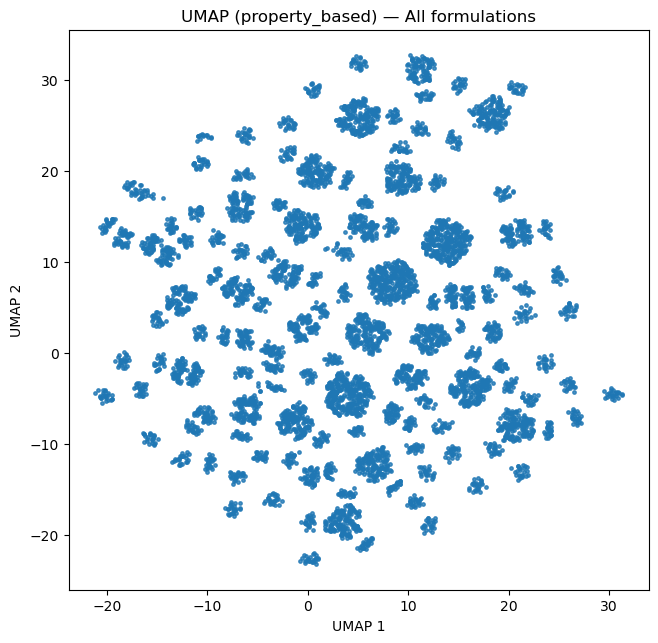

C:\Users\洪家賢\AppData\Local\Temp\ipykernel_32060\613237807.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


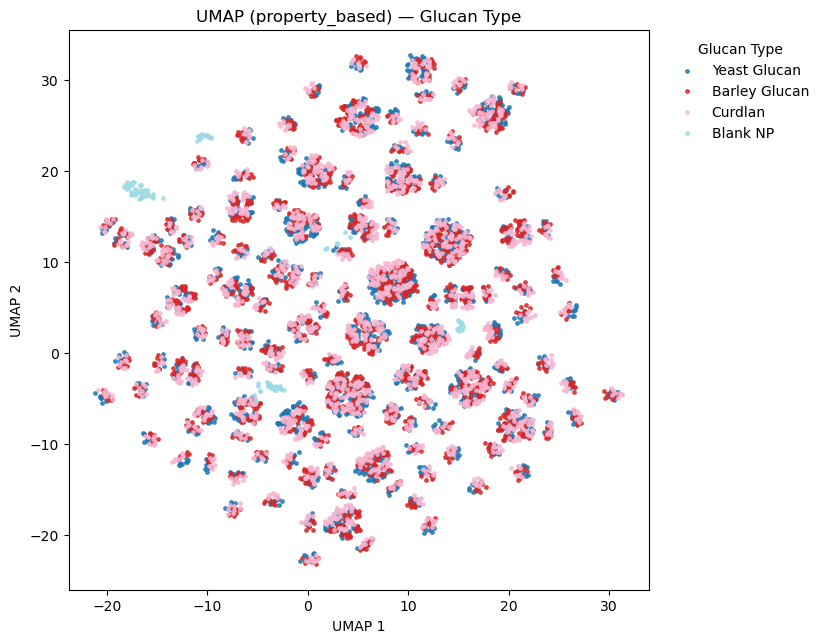

C:\Users\洪家賢\AppData\Local\Temp\ipykernel_32060\613237807.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


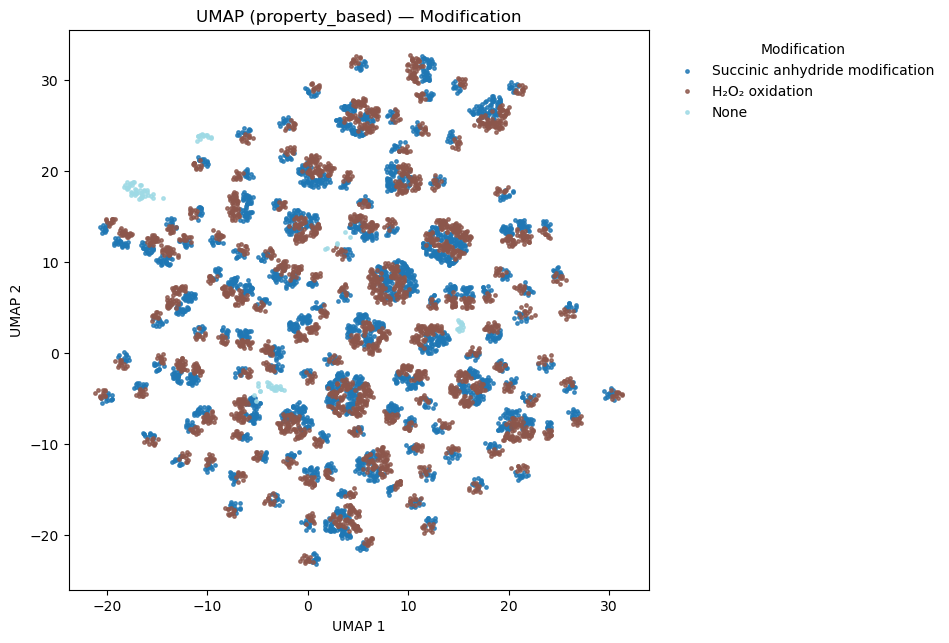

C:\Users\洪家賢\AppData\Local\Temp\ipykernel_32060\613237807.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


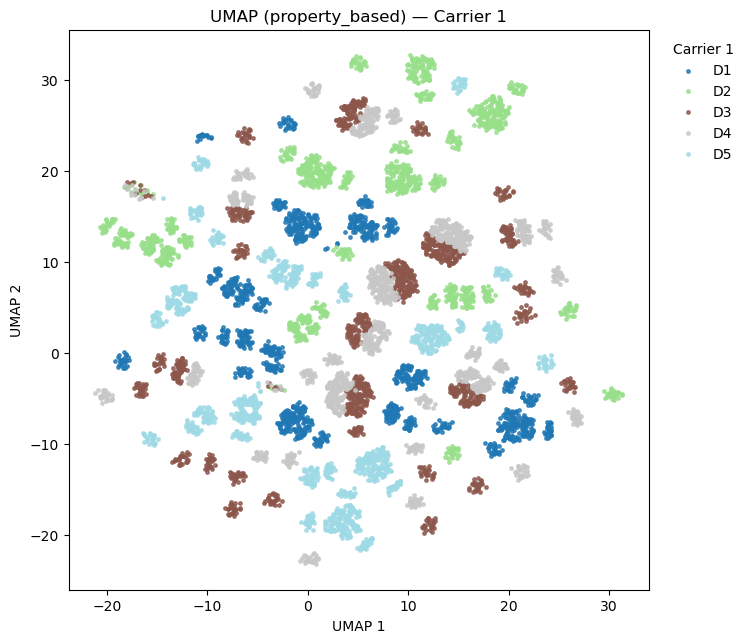

C:\Users\洪家賢\AppData\Local\Temp\ipykernel_32060\613237807.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


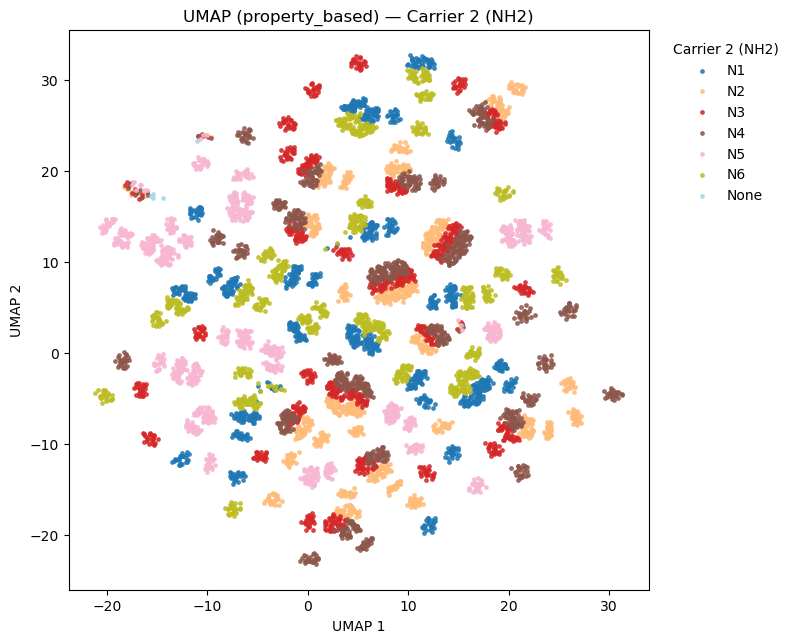

C:\Users\洪家賢\AppData\Local\Temp\ipykernel_32060\613237807.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


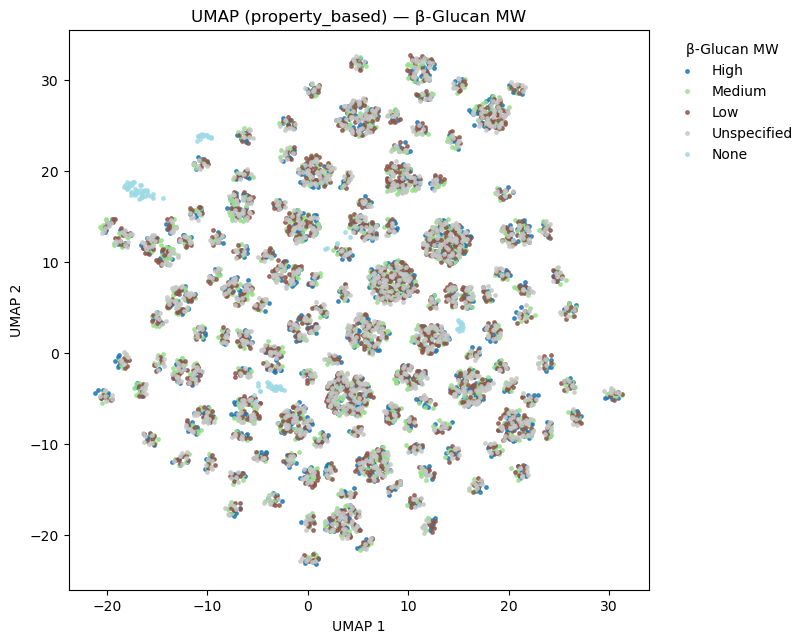

C:\Users\洪家賢\AppData\Local\Temp\ipykernel_32060\613237807.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


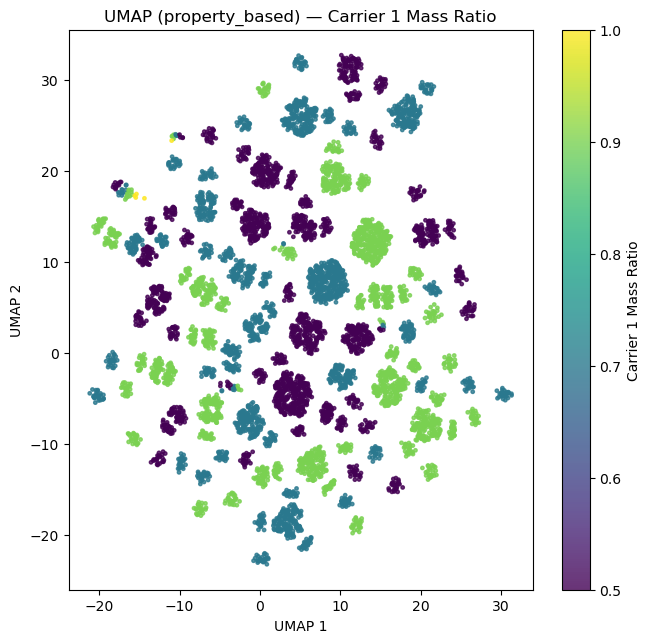

C:\Users\洪家賢\AppData\Local\Temp\ipykernel_32060\613237807.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


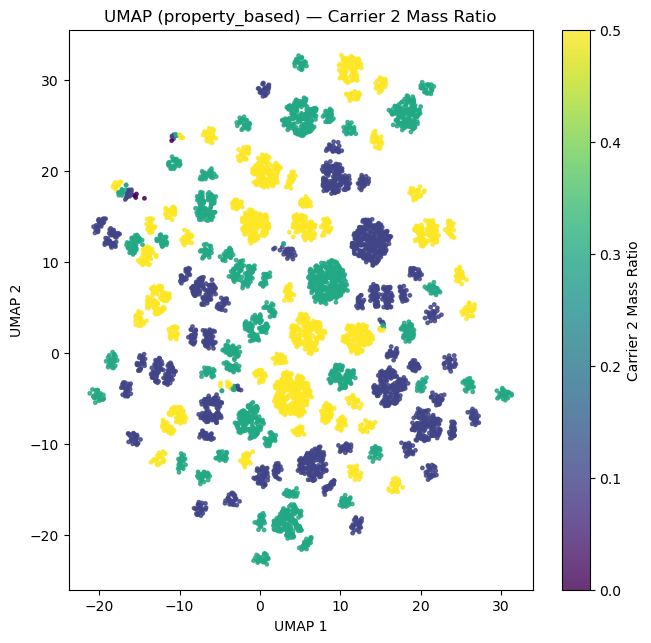

C:\Users\洪家賢\AppData\Local\Temp\ipykernel_32060\613237807.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


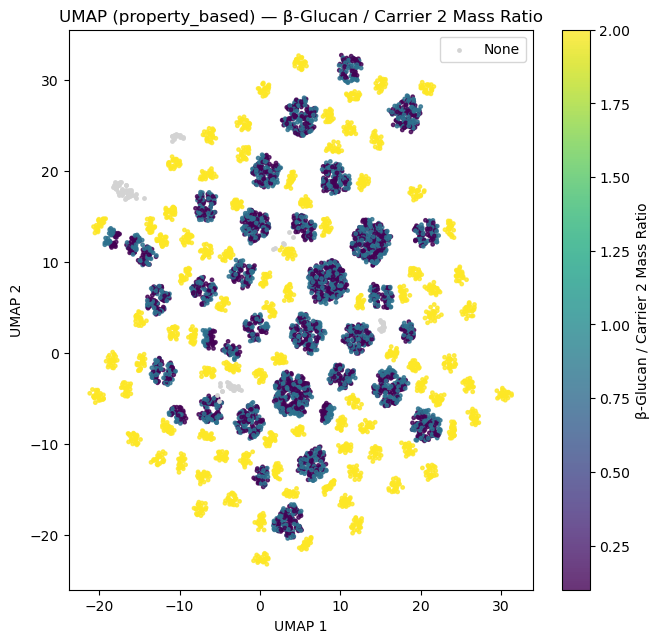

Results: C:\Users\洪家賢\NAS\AI code\Nanoparticle-AI-Optimization\results\umap\property_based
Figures: C:\Users\洪家賢\NAS\AI code\Nanoparticle-AI-Optimization\results\figures\umap\property_based


In [6]:

def plot_umap(table, color_by=None):
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_axes([0.10, 0.12, 0.58, 0.80])
    if color_by is None:
        ax.scatter(table.UMAP_1, table.UMAP_2, s=6, alpha=0.8)
    elif color_by in numeric_plot_cols:
        values = pd.to_numeric(table[color_by], errors="coerce")
        valid = values.notna()
        if valid.any():
            points = ax.scatter(table.loc[valid, "UMAP_1"], table.loc[valid, "UMAP_2"],
                                c=values[valid], cmap="viridis", s=6, alpha=0.8)
            fig.colorbar(points, ax=ax, label=color_by)
        if (~valid).any():
            ax.scatter(table.loc[~valid, "UMAP_1"], table.loc[~valid, "UMAP_2"],
                       c="lightgray", s=6, label="None")
            ax.legend()
    else:
        labels = table[color_by].fillna("None").astype(str)
        categories = get_legend_order(labels, color_by)
        colors = plt.get_cmap("tab20", max(len(categories), 1))
        for i, category in enumerate(categories):
            mask = labels == category
            ax.scatter(table.loc[mask, "UMAP_1"], table.loc[mask, "UMAP_2"],
                       label=category, color=colors(i), s=6, alpha=0.8)
        ax.legend(title=color_by, bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    ax.set(xlabel="UMAP 1", ylabel="UMAP 2",
           title=f"UMAP ({FEATURE_SET}) — {color_by or 'All formulations'}")
    fig.tight_layout()
    stem = "all" if color_by is None else "".join(c if c.isalnum() else "_" for c in color_by)
    fig.savefig(FIGURE_DIR / f"umap_{stem}.png", dpi=300)
    fig.savefig(FIGURE_DIR / f"umap_{stem}.pdf")
    plt.show()
    plt.close(fig)

plot_umap(result)
for col in label_cols:
    if col in result:
        plot_umap(result, col)

result.to_csv(RESULT_DIR / "umap_coordinates.csv", index=False)
config = {
    "feature_set": FEATURE_SET, "input": str(FEATURE_FILE),
    "n_samples": len(X), "feature_columns": X.columns.tolist(),
    "removed_constant_columns": constant_cols,
    "removed_carrier_identity_columns": removed_identity_cols,
    "trustworthiness_sample_size": len(quality_indices),
    "n_neighbors": effective_neighbors, "min_dist": MIN_DIST, "spread": SPREAD, "metric": METRIC,
    "random_state": RANDOM_STATE, "init": "random",
    "trustworthiness_k": quality_k, "trustworthiness": float(quality),
    "versions": {p: importlib.metadata.version(p) for p in
                 ["umap-learn", "numpy", "pandas", "scikit-learn", "matplotlib"]},
}
(RESULT_DIR / "umap_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print("Results:", RESULT_DIR)
print("Figures:", FIGURE_DIR)


## Build an overview figure

Combine Carrier 1, Carrier 2, glucan source, and modification plots in a four-panel figure using the same embedding coordinates.

Export the overview as a 200 dpi PNG and a PDF. Overlapping points can be inspected more closely in the interactive plot.


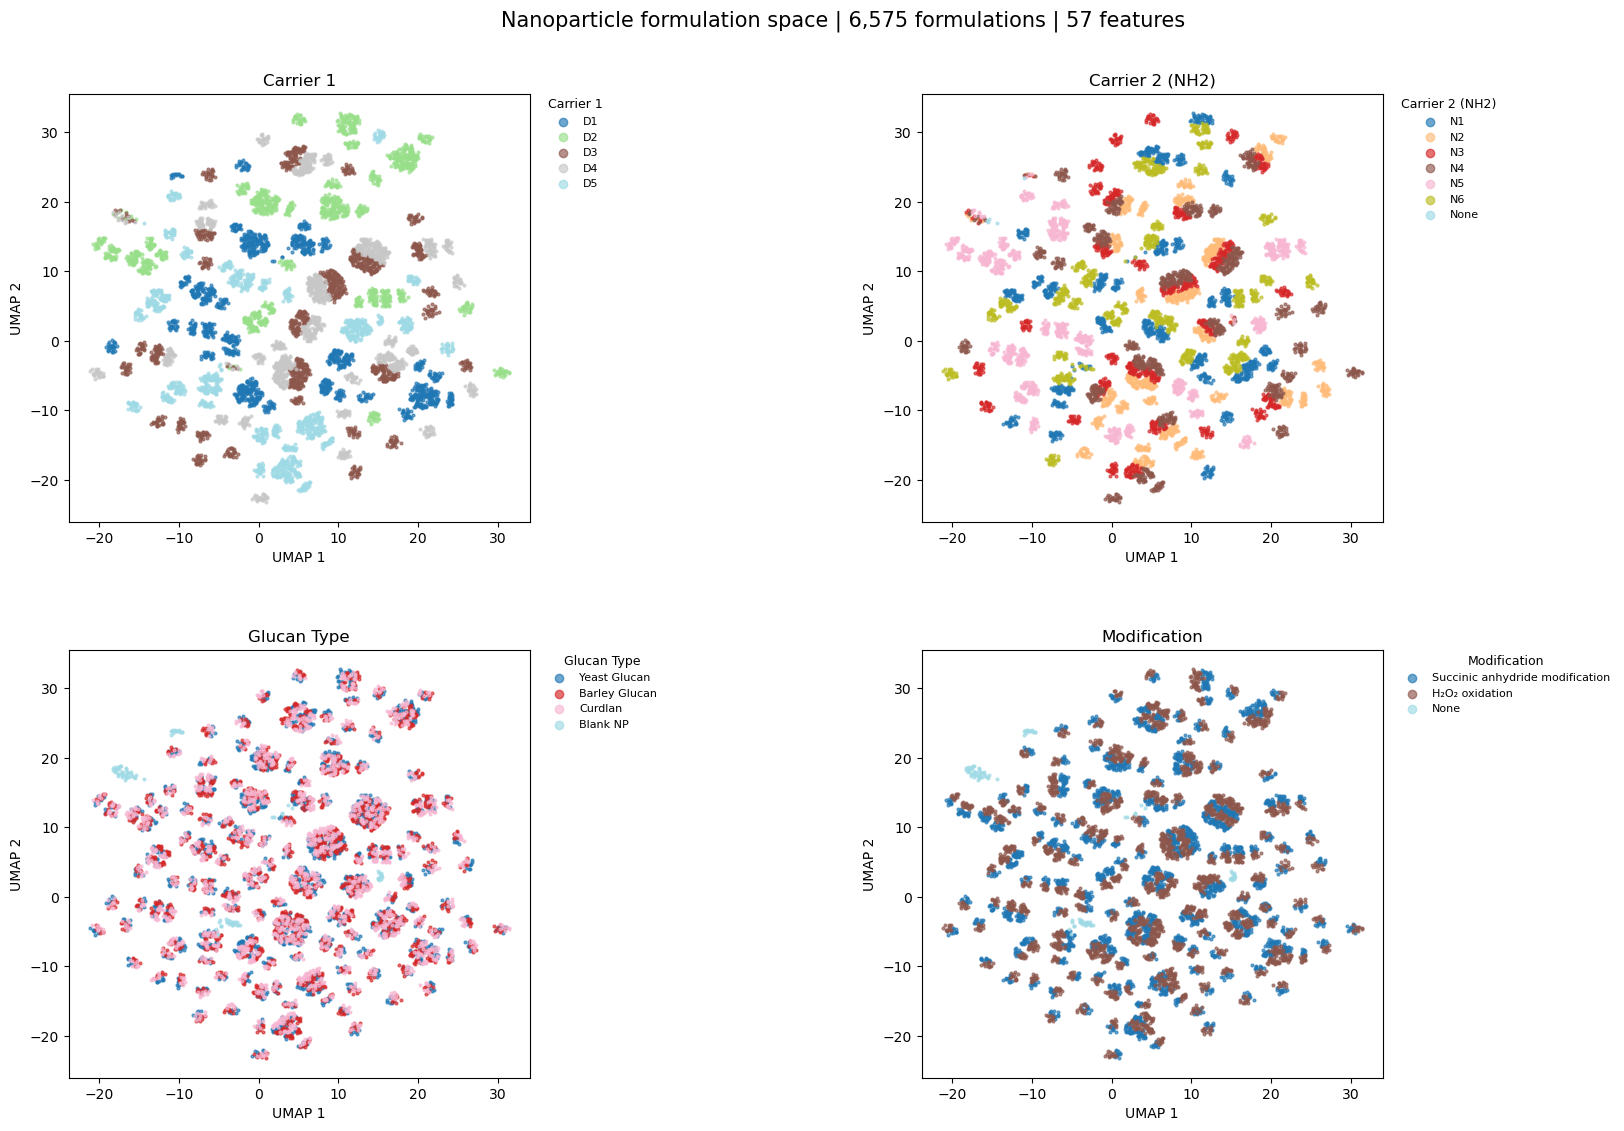

In [7]:
overview_cols = [
    col for col in [
        "Carrier 1",
        "Carrier 2 (NH2)",
        "Glucan Type",
        "Modification",
    ]
    if col in result.columns
]

if overview_cols:
    fig, axes = plt.subplots(2, 2, figsize=(18, 12))

    # Reserve consistent space for axes and legends.
    fig.subplots_adjust(
        left=0.07,
        right=0.80,
        bottom=0.08,
        top=0.90,
        wspace=0.85,
        hspace=0.30,
    )

    # Use identical coordinate limits in every panel.
    x_min, x_max = result["UMAP_1"].min(), result["UMAP_1"].max()
    y_min, y_max = result["UMAP_2"].min(), result["UMAP_2"].max()

    x_pad = max((x_max - x_min) * 0.05, 0.1)
    y_pad = max((y_max - y_min) * 0.05, 0.1)

    for ax, col in zip(axes.flat, overview_cols):
        labels = result[col].fillna("None").astype(str)
        categories = get_legend_order(labels, col)
        cmap = plt.get_cmap("tab20", max(len(categories), 1))

        for i, category in enumerate(categories):
            mask = labels == category

            ax.scatter(
                result.loc[mask, "UMAP_1"],
                result.loc[mask, "UMAP_2"],
                s=4,
                alpha=0.65,
                color=cmap(i),
                label=category,
                rasterized=True,
            )

        ax.set(
            title=col,
            xlabel="UMAP 1",
            ylabel="UMAP 2",
            xlim=(x_min - x_pad, x_max + x_pad),
            ylim=(y_min - y_pad, y_max + y_pad),
        )

        ax.legend(
            title=col,
            fontsize=8,
            title_fontsize=9,
            markerscale=3,
            bbox_to_anchor=(1.03, 1),
            loc="upper left",
            borderaxespad=0,
            frameon=False,
        )

    for ax in list(axes.flat)[len(overview_cols):]:
        ax.set_visible(False)

    fig.suptitle(
        f"Nanoparticle formulation space | "
        f"{len(result):,} formulations | {X.shape[1]} features",
        fontsize=15,
        y=0.97,
    )

    FIGURE_DIR.mkdir(parents=True, exist_ok=True)

    # Preserve the fixed canvas dimensions.
    fig.savefig(FIGURE_DIR / "umap_overview.png", dpi=200)
    fig.savefig(FIGURE_DIR / "umap_overview.pdf")

    plt.show()
    plt.close(fig)


## Create an interactive plot

Create an optional Plotly scatter plot with formulation IDs and available metadata displayed on hover. Carrier 1 is used for coloring when available.

Export a standalone HTML file with embedded Plotly resources for offline viewing. If Plotly is unavailable, the notebook skips this step and displays installation instructions.


In [8]:
try:
    import plotly.express as px
except ImportError:
    print("Optional interactive plot: install plotly with %pip install plotly")
else:
    interactive = result.copy()
    color_col = "Carrier 1" if "Carrier 1" in interactive else None
    if color_col:
        interactive[color_col] = interactive[color_col].fillna("None")
    fig = px.scatter(interactive, x="UMAP_1", y="UMAP_2", color=color_col,
                     hover_name="ID", hover_data=[c for c in label_cols if c in interactive],
                     title=f"Formulation design space — {FEATURE_SET}", template="simple_white",
                     category_orders={color_col: category_orders.get(color_col, [])} if color_col else None)
    fig.write_html(RESULT_DIR / "umap_interactive.html", include_plotlyjs=True)
    fig.show()
